# 횡단보도·보행신호 모델 비교 (YOLO26n / YOLO26s / YOLO11s, Kaggle)
- 데이터: 재분할한 데이터셋을 **Private** 으로 올리고 Add Input (`data.yaml` 이 들어 있으면 경로는 자동으로 찾음)
- 설정: Accelerator **GPU T4**, **Internet On**
- **Save Version → Save & Run All (Commit)** 으로 돌려. 브라우저를 닫아도 끝까지 돌고 결과가 Output 에 남아.
- 흐름: 라벨 정리(좌표 클리핑) → 모델 3개를 같은 조건(640, 50 epoch, seed 0)으로 학습 → 같은 test 로 평가 → `compare.csv`
- 예상 시간(T4): 11s 약 1시간 20분, 26s 비슷, 26n 더 빠름 → 합계 3~4시간 (12시간 제한 안)
- 끝나면 1등 모델만 960 으로 재학습하는 셀(맨 아래)은 별도 실행

In [1]:
!pip install -q -U ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 5.5 MB/s eta 0:00:00


In [2]:
import glob, os, re, time, json, shutil
import numpy as np, pandas as pd, torch, yaml
from ultralytics import YOLO
from ultralytics.utils.metrics import box_iou

# 설정 ------------------------------------------------------------
MODELS = ['yolo26n.pt', 'yolo26s.pt', 'yolo11s.pt']   # 비교할 모델
IMGSZ  = 640          # 비교는 640, 고른 모델만 나중에 960
EPOCHS = 50
SEED   = 0
CONF   = 0.25         # 색 오류·놓침 계산에 쓰는 실제 사용 임계값
OUT    = '/kaggle/working/runs'
DS     = '/kaggle/working/ds'          # 라벨만 정리한 사본 (이미지는 링크)

found = sorted(glob.glob('/kaggle/input/**/data.yaml', recursive=True))
if not found:
    for p in glob.glob('/kaggle/input/*/*')[:20]: print(p)
    raise SystemExit('data.yaml 을 못 찾음: 오른쪽 Input 에 데이터셋을 추가했는지 확인 (위에 /kaggle/input 내용 출력)')
SRC_YAML = found[0]
SRC = os.path.dirname(SRC_YAML)
print('data :', SRC_YAML)
print('gpu  :', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'GPU 없음 -> Accelerator 를 GPU 로')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
data : /kaggle/input/datasets/juhyun9/one-step/data.yaml
gpu  : Tesla T4


## 1. 라벨 정리 (원본은 그대로, /kaggle/working 에 사본)
- 좌표가 0~1 밖이면 잘라내고, 잘린 뒤 너무 작으면 버림 (지난번 corrupt 6장 원인)
- 폴리곤 줄(숫자 5개 초과)은 박스로 변환
- 이미지는 파일마다 심볼릭 링크라 용량·시간 거의 안 듦

In [3]:
names = yaml.safe_load(open(SRC_YAML))['names']
if isinstance(names, dict): names = [names[k] for k in sorted(names)]
SPLITS = {'train': 'train', 'val': 'valid', 'test': 'test'}
stat = dict(files=0, clipped=0, dropped=0, poly=0)
shutil.rmtree(DS, ignore_errors=True)
for key, sp in SPLITS.items():
    src_img = f'{SRC}/{sp}/images'
    if not os.path.isdir(src_img):
        raise SystemExit(f'{src_img} 없음: export 폴더 구조 확인')
    os.makedirs(f'{DS}/{sp}/labels'); os.makedirs(f'{DS}/{sp}/images')
    for f in os.listdir(src_img):                 # 파일마다 링크 (폴더 링크는 Ultralytics 가 원본 경로로 풀어버림)
        os.symlink(f'{src_img}/{f}', f'{DS}/{sp}/images/{f}')
    for lf in glob.glob(f'{SRC}/{sp}/labels/*.txt'):
        out = []
        for line in open(lf):
            v = line.split()
            if len(v) < 5: continue
            c, xy = v[0], list(map(float, v[1:]))
            if len(xy) > 4:                       # 폴리곤 -> 박스
                xs, ys = xy[0::2], xy[1::2]; stat['poly'] += 1
                x1, y1, x2, y2 = min(xs), min(ys), max(xs), max(ys)
            else:
                x, y, w, h = xy; x1, y1, x2, y2 = x - w/2, y - h/2, x + w/2, y + h/2
            cx1, cy1, cx2, cy2 = max(0, x1), max(0, y1), min(1, x2), min(1, y2)
            if (cx1, cy1, cx2, cy2) != (x1, y1, x2, y2): stat['clipped'] += 1
            if cx2 - cx1 < 0.002 or cy2 - cy1 < 0.002: stat['dropped'] += 1; continue
            out.append(f'{c} {(cx1+cx2)/2:.6f} {(cy1+cy2)/2:.6f} {cx2-cx1:.6f} {cy2-cy1:.6f}\n')
        open(f'{DS}/{sp}/labels/{os.path.basename(lf)}', 'w').writelines(out)
        stat['files'] += 1
DATA = '/kaggle/working/data.yaml'
yaml.safe_dump(dict(path=DS, train='train/images', val='valid/images', test='test/images',
                    nc=len(names), names=names), open(DATA, 'w'), allow_unicode=True)
print(stat)
for sp in SPLITS.values():
    n_img = len(os.listdir(f'{DS}/{sp}/images')); n_lab = len(os.listdir(f'{DS}/{sp}/labels'))
    print(f'{sp:6} 이미지 {n_img}  라벨 {n_lab}')
print(open(DATA).read())

{'files': 6549, 'clipped': 0, 'dropped': 25, 'poly': 0}
train  이미지 4584  라벨 4584
valid  이미지 983  라벨 983
test   이미지 982  라벨 982
names:
- crosswalk
- green-crossing
- red-crossing
nc: 3
path: /kaggle/working/ds
test: test/images
train: train/images
val: valid/images



## 2. 평가 함수
- Ultralytics test 지표 (전체·클래스별 P/R/AP50/AP50-95, 속도)
- 신호 색 오류: 정답 신호마다 IoU>0.5 인 신호 예측 중 **점수 1등 하나만** 보고 판단 (conf 0.25)
  → 지난번 37%/46% 같은 잘못된 숫자가 안 나옴

In [4]:
GREEN, RED = names.index('green-crossing'), names.index('red-crossing')
CW = names.index('crosswalk')

def color_errors(weights):
    m = YOLO(weights)
    st = {GREEN: [0, 0, 0], RED: [0, 0, 0]}          # [맞음, 색틀림, 놓침]
    wrong = []
    for r in m.predict(f'{DS}/test/images', imgsz=IMGSZ, conf=CONF, stream=True, verbose=False, device=0):
        lf = f"{DS}/test/labels/{os.path.splitext(os.path.basename(r.path))[0]}.txt"
        if not os.path.exists(lf) or os.path.getsize(lf) == 0: continue
        gt = np.loadtxt(lf, ndmin=2)
        h, w = r.orig_shape
        pb, pc, ps = r.boxes.xyxy.cpu(), r.boxes.cls.cpu().int(), r.boxes.conf.cpu()
        for c, x, y, bw, bh in gt[:, :5]:
            c = int(c)
            if c not in st: continue
            g = torch.tensor([[(x-bw/2)*w, (y-bh/2)*h, (x+bw/2)*w, (y+bh/2)*h]])
            cand = (box_iou(g, pb)[0] > 0.5) & (pc != CW) if len(pb) else torch.zeros(0, dtype=torch.bool)
            if not cand.any(): st[c][2] += 1; continue
            best = torch.where(cand, ps, torch.tensor(-1.)).argmax()
            if pc[best] == c: st[c][0] += 1
            else: st[c][1] += 1; wrong.append((os.path.basename(r.path), names[c], float(ps[best])))
    return st, wrong

def evaluate(weights, tag):
    v = YOLO(weights).val(data=DATA, split='test', imgsz=IMGSZ, batch=16, device=0,
                          project=OUT, name=f'test_{tag}', exist_ok=True, plots=True)
    row = dict(model=tag, mAP50=v.box.map50, mAP50_95=v.box.map, P=v.box.mp, R=v.box.mr,
               infer_ms=v.speed['inference'])
    for i, c in enumerate(v.box.ap_class_index):
        p, r, ap50, ap = v.box.class_result(i)
        n = names[int(c)]
        row.update({f'{n}_P': p, f'{n}_R': r, f'{n}_AP50': ap50, f'{n}_AP50_95': ap})
    st, wrong = color_errors(weights)
    for c, n in [(RED, 'red'), (GREEN, 'green')]:
        ok, bad, miss = st[c]; t = max(1, sum(st[c]))
        row[f'{n}_wrongcolor_%'] = 100 * bad / t
        row[f'{n}_miss_%'] = 100 * miss / t
    if wrong: print('색 틀린 신호:', wrong[:10])
    return row

## 3. 학습 + 평가 (모델 3개, 같은 조건)
- 이미 끝난 모델은 건너뜀 (중간에 끊겨도 다시 Run All 하면 이어서 함)
- 결과는 모델마다 `compare.csv` 에 바로 저장

In [5]:
CSV = '/kaggle/working/compare.csv'
rows = pd.read_csv(CSV).to_dict('records') if os.path.exists(CSV) else []
done = {r['model'] for r in rows}

for w in MODELS:
    tag = os.path.splitext(w)[0] + f'_{IMGSZ}'
    if tag in done:
        print(tag, '이미 평가됨 -> 건너뜀'); continue
    best = f'{OUT}/{tag}/weights/best.pt'
    t0 = time.time()
    if not os.path.exists(best):
        model = YOLO(w)
        model.train(data=DATA, imgsz=IMGSZ, epochs=EPOCHS, batch=-1, device=0, workers=4,
                    seed=SEED, deterministic=False, project=OUT, name=tag, exist_ok=True)
    train_min = (time.time() - t0) / 60
    row = evaluate(best, tag)
    try:
        info = YOLO(best).info(verbose=False)        # (layers, params, gradients, GFLOPs)
        row.update(params_M=info[1] / 1e6, GFLOPs=info[3])
    except Exception as e:
        print('info 실패(무시):', e)
    row['train_min'] = train_min
    rows.append(row)
    pd.DataFrame(rows).to_csv(CSV, index=False)
    print(f'\n== {tag} 끝: mAP50 {row["mAP50"]:.3f}, mAP50-95 {row["mAP50_95"]:.3f}, {train_min:.0f}분 ==\n')
    torch.cuda.empty_cache()

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26n_640, nbs=64, nms=None, opset=None, optimize=False, opti

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/50      6.02G      1.372      1.435    0.01554        107        640: 100% ━━━━━━━━━━━━ 115/115 2.5it/s 45.6s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 1.9it/s 6.7s
                   all        983       1476      0.714       0.64      0.687      0.353

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/50      7.09G      1.394      1.173    0.01619         83        640: 100% ━━━━━━━━━━━━ 115/115 2.6it/s 45.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 1.9it/s 6.8s
                   all        983       1476      0.653      0.595       0.62      0.305

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/50      7.09G      1.383      1.082    0.01595        112        640: 100% ━━━━━━━━━━━━ 115/115 2.5it/s 45.1s
                 Class     Images  Instances      Box

## 4. 비교표

In [6]:
df = pd.read_csv('/kaggle/working/compare.csv')
main = ['model', 'mAP50', 'mAP50_95', 'P', 'R',
        'crosswalk_R', 'crosswalk_AP50_95', 'green-crossing_AP50', 'red-crossing_AP50',
        'red_wrongcolor_%', 'red_miss_%', 'green_wrongcolor_%', 'green_miss_%',
        'infer_ms', 'params_M', 'GFLOPs', 'train_min']
show = df[[c for c in main if c in df.columns]].copy()
pd.set_option('display.width', 250)
print(show.round(3).to_string(index=False))

# 고르는 기준: 빨간불 색 오류가 가장 적고 -> mAP50-95 -> 속도
best = show.sort_values(['red_wrongcolor_%', 'mAP50_95', 'infer_ms'], ascending=[True, False, True]).iloc[0]
print('\n추천:', best['model'], '(빨간불 색오류 -> mAP50-95 -> 속도 순으로 정렬한 1등)')
print('차이가 0.01 이내면 더 빠른(작은) 모델을 고르는 걸 추천')

      model  mAP50  mAP50_95     P     R  crosswalk_R  crosswalk_AP50_95  green-crossing_AP50  red-crossing_AP50  red_wrongcolor_%  red_miss_%  green_wrongcolor_%  green_miss_%  infer_ms  train_min
yolo26n_640  0.862     0.554 0.874 0.805        0.755              0.607                0.878              0.874               0.0      16.997               0.601        11.411     4.958     75.097
yolo26s_640  0.866     0.568 0.865 0.804        0.756              0.606                0.888              0.884               0.0      14.448               0.601         9.610    11.728     76.264
yolo11s_640  0.831     0.535 0.858 0.771        0.726              0.568                0.812              0.868               0.0      15.864               0.901        15.616    11.255     60.665

추천: yolo26s_640 (빨간불 색오류 -> mAP50-95 -> 속도 순으로 정렬한 1등)
차이가 0.01 이내면 더 빠른(작은) 모델을 고르는 걸 추천


/kaggle/working/runs/yolo26n_640/results.png


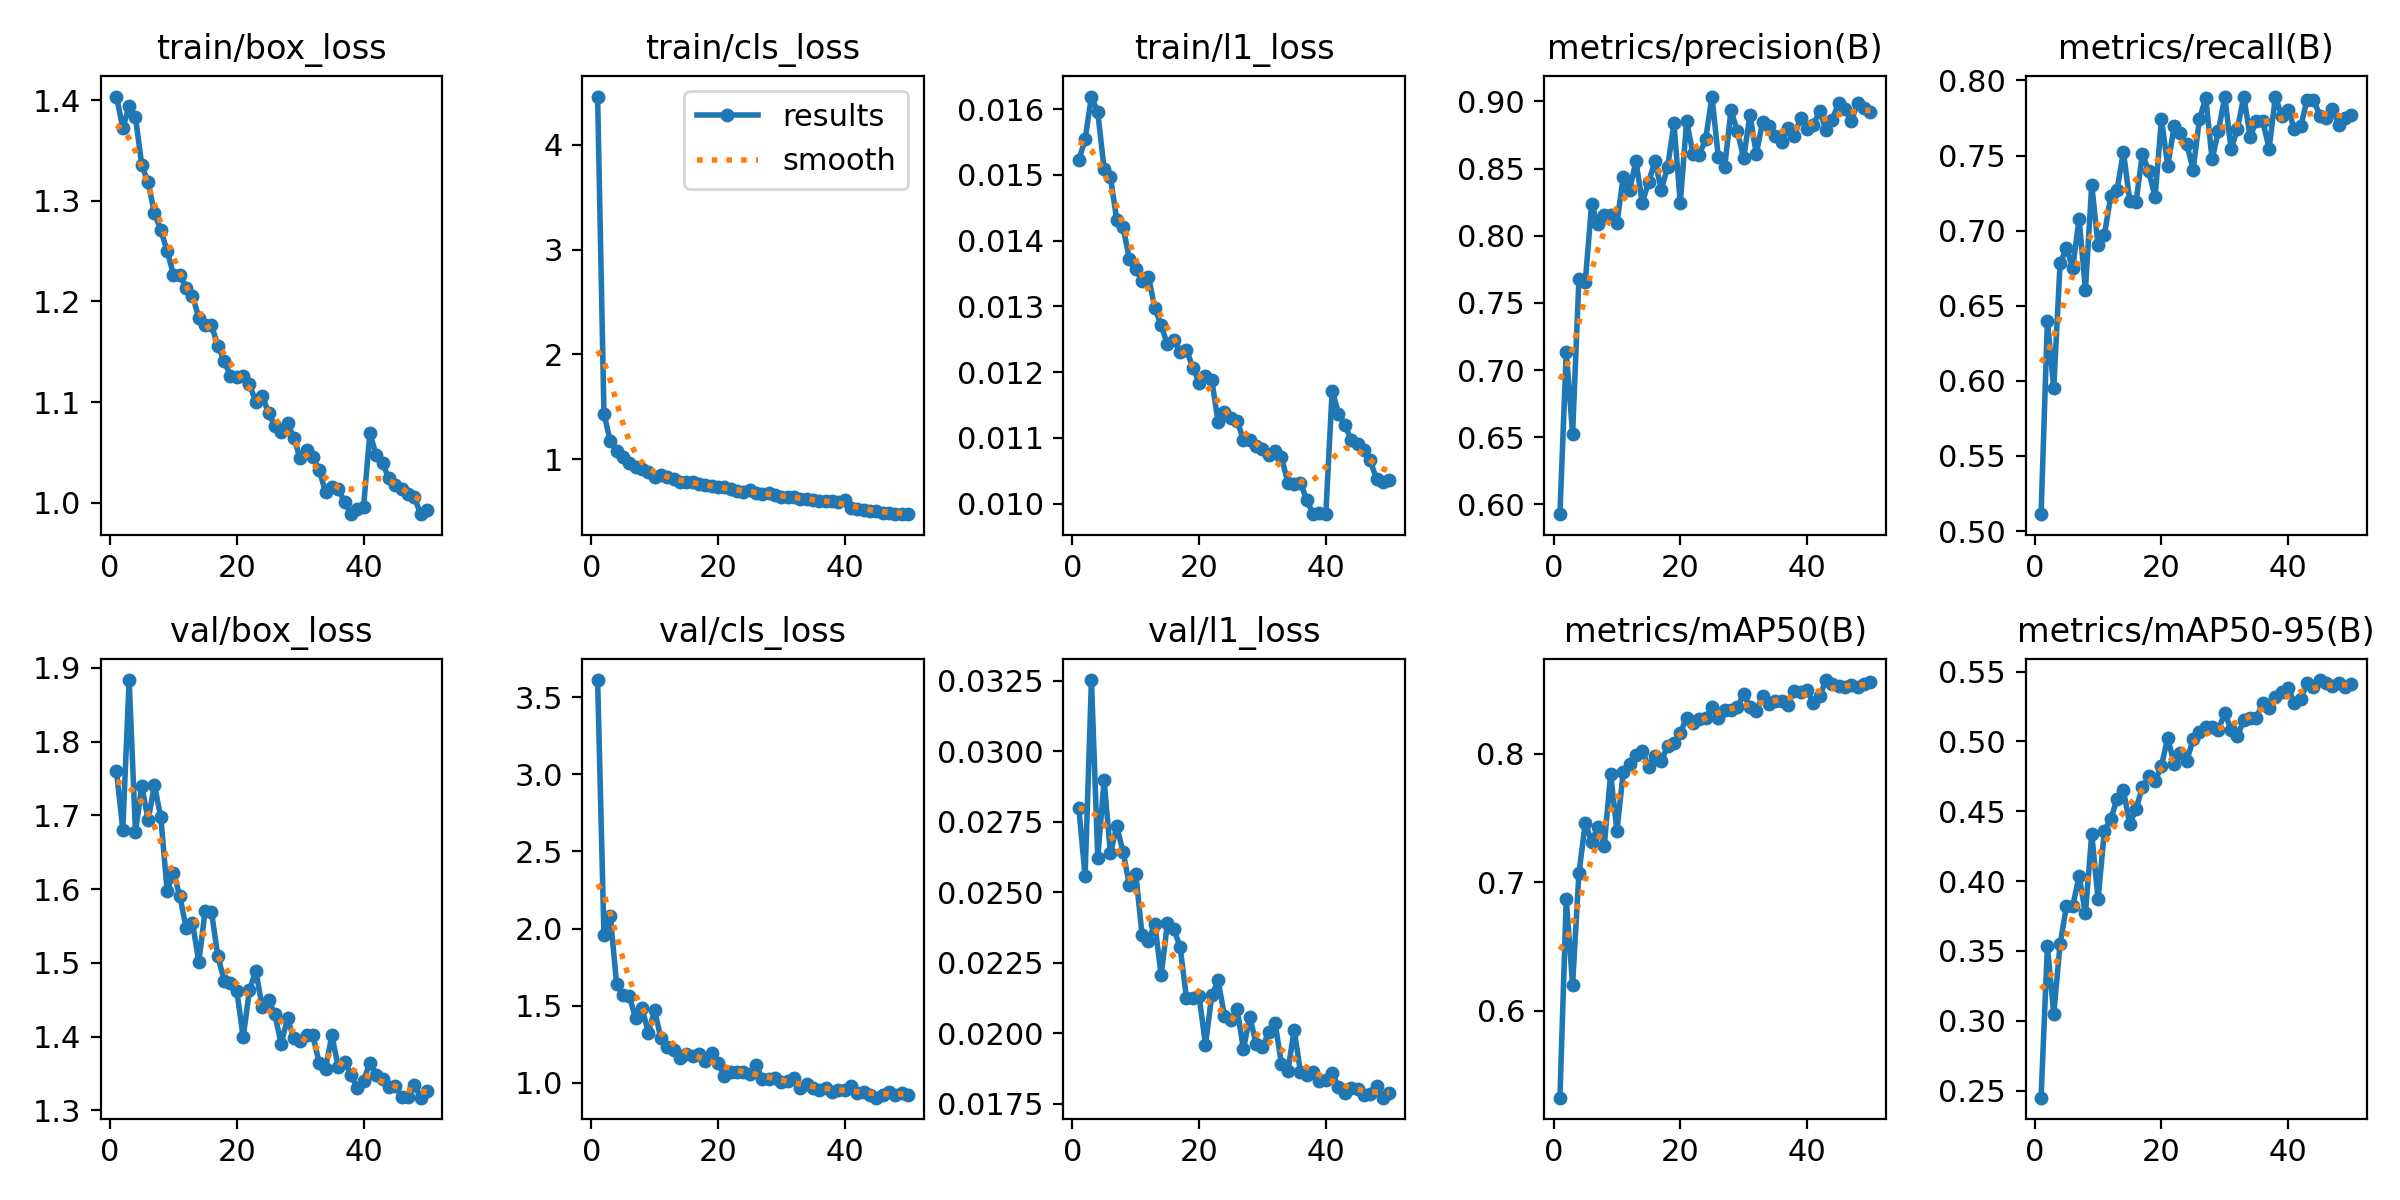

/kaggle/working/runs/test_yolo26n_640/confusion_matrix_normalized.png


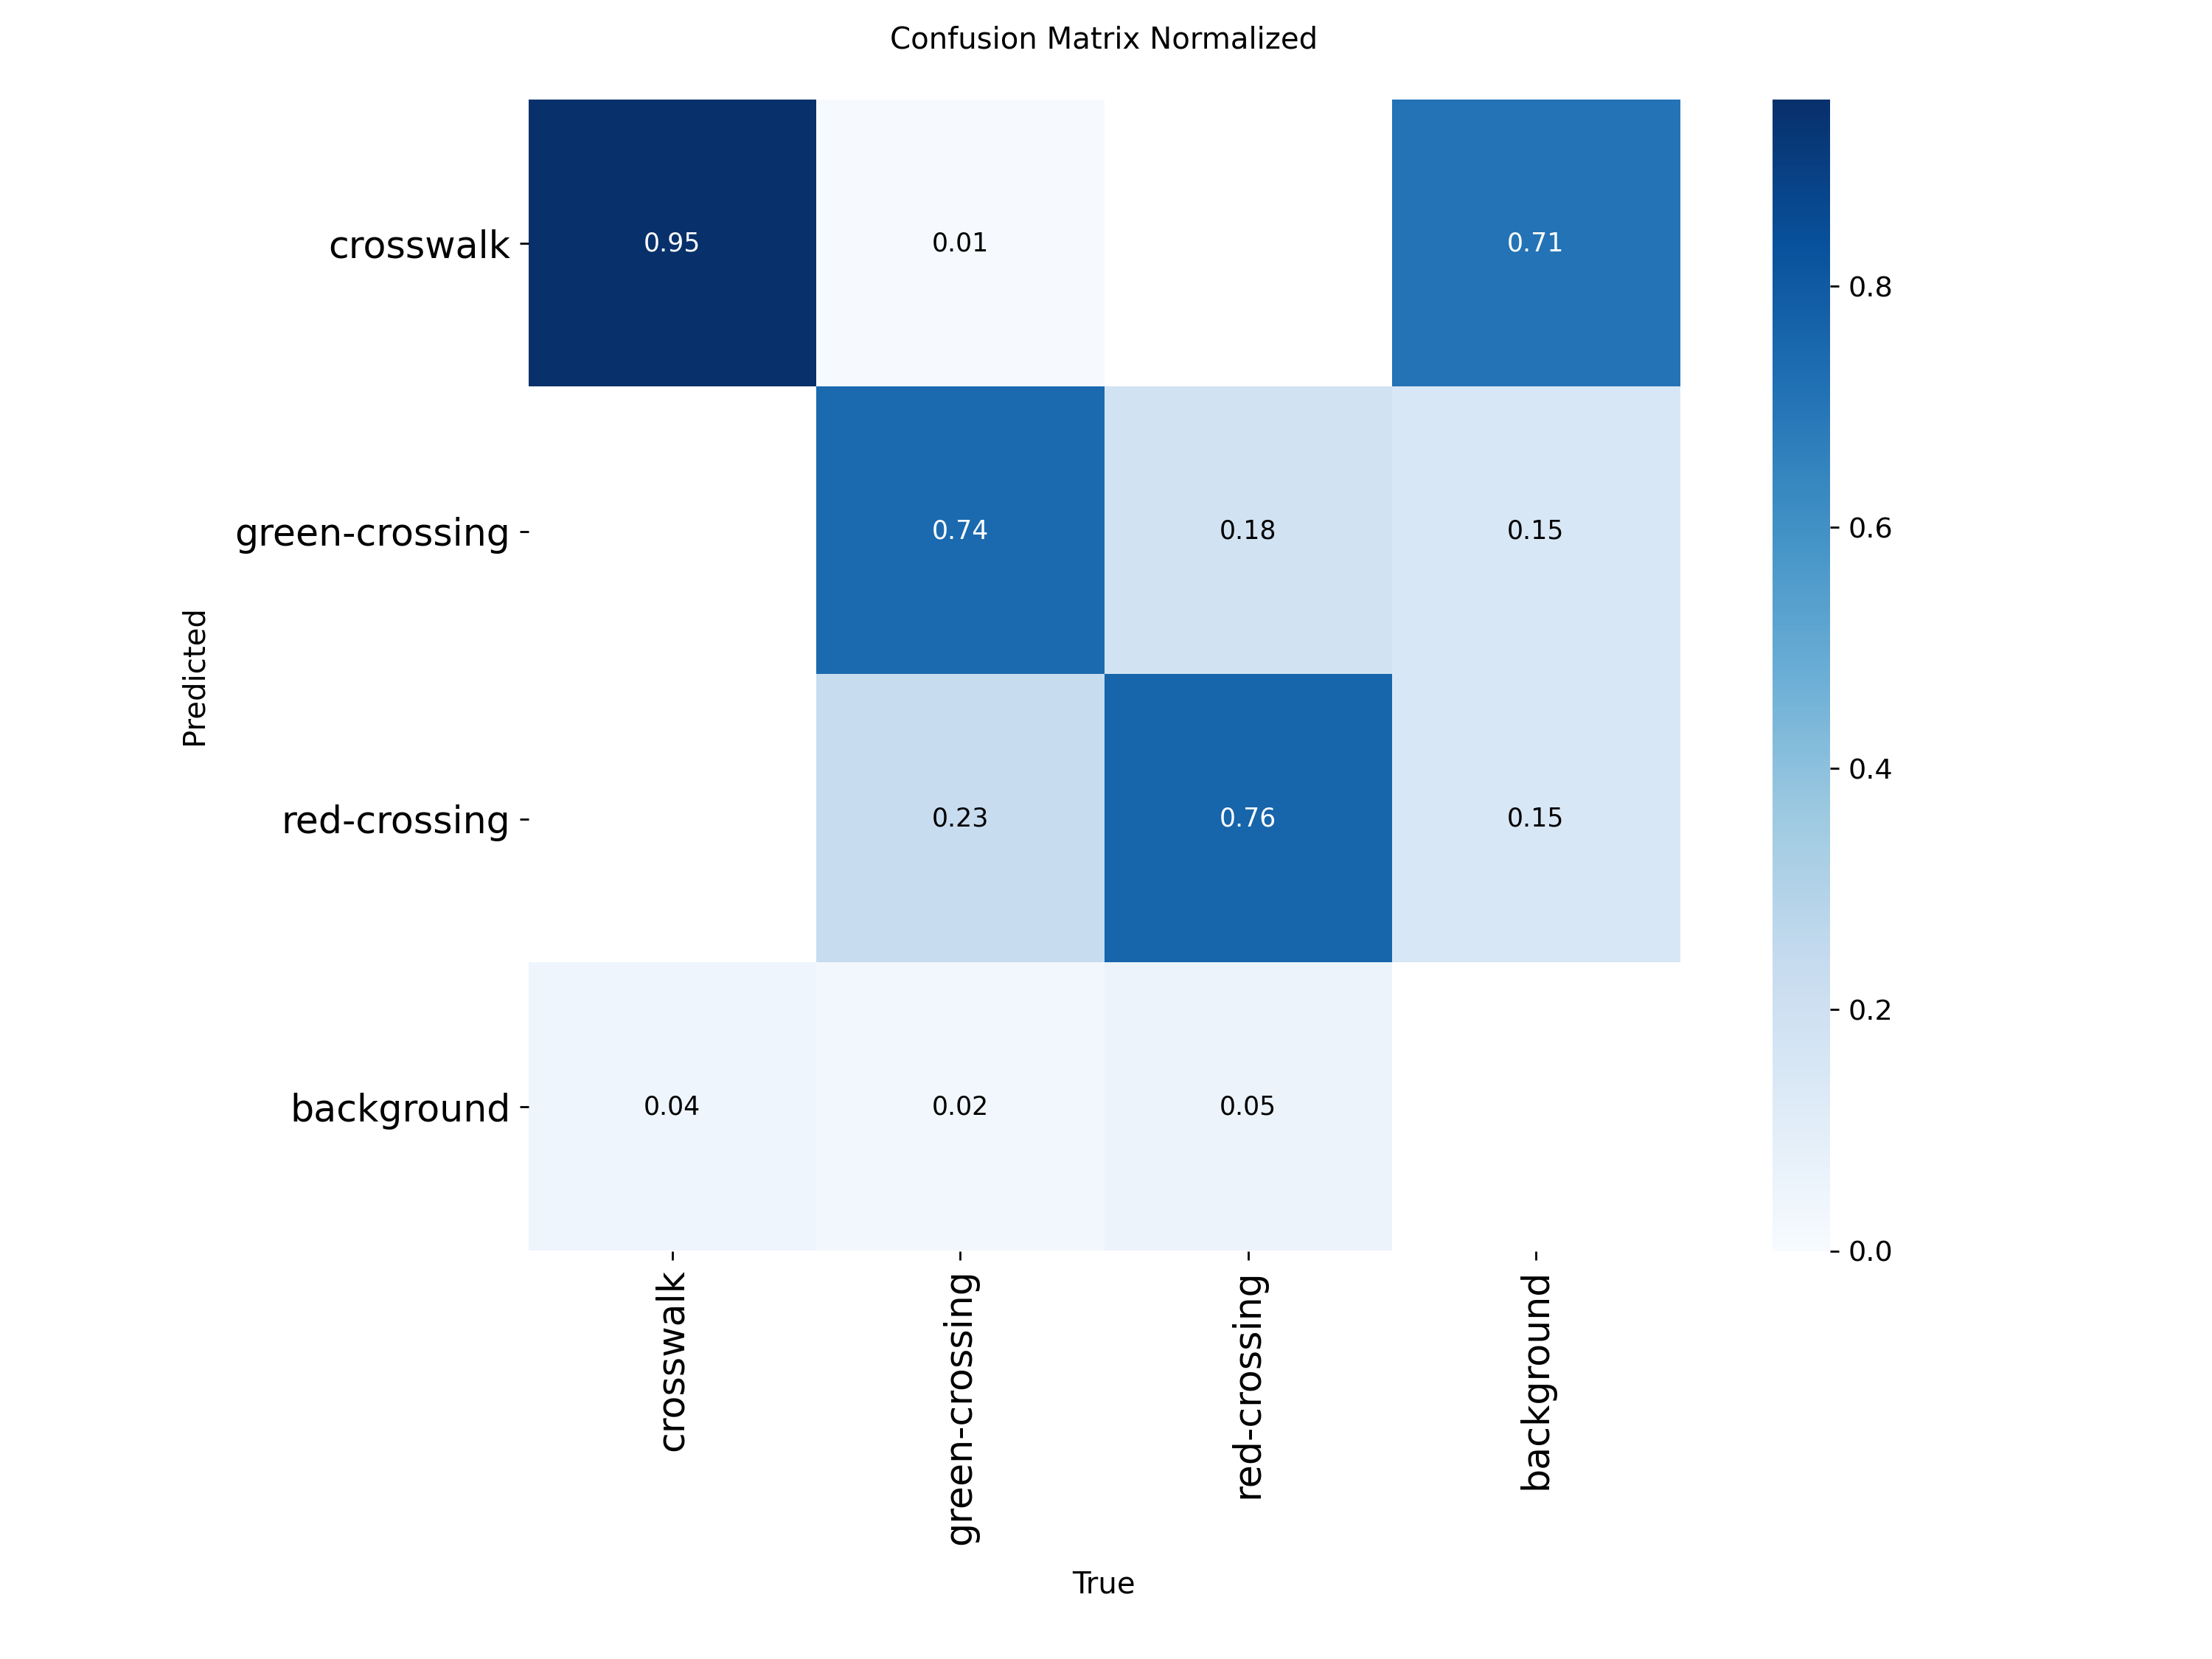

/kaggle/working/runs/yolo26s_640/results.png


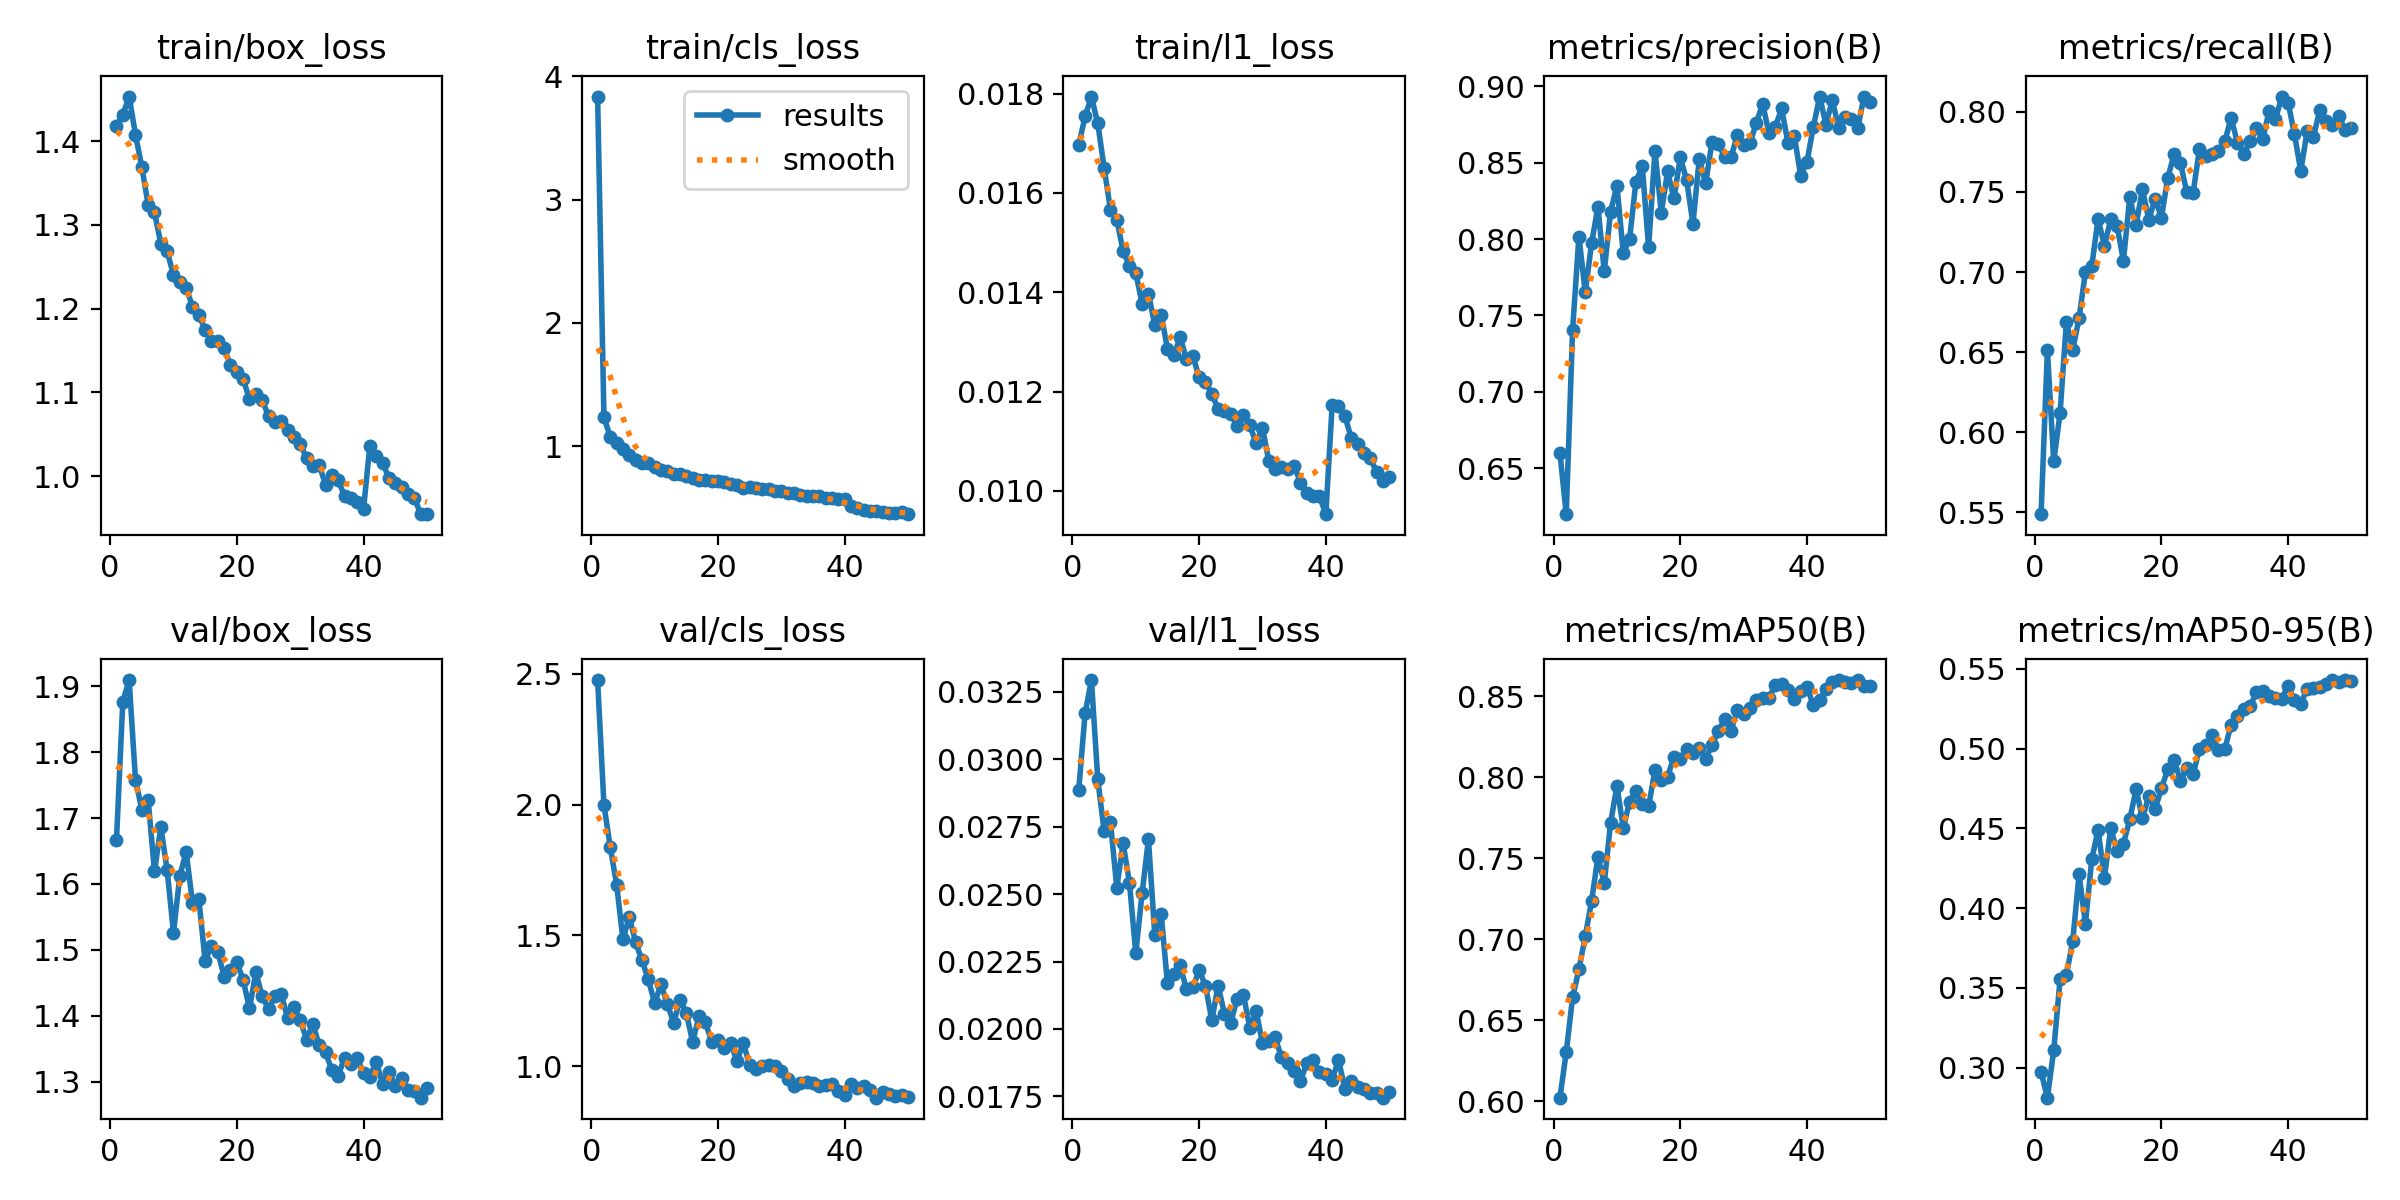

/kaggle/working/runs/test_yolo26s_640/confusion_matrix_normalized.png


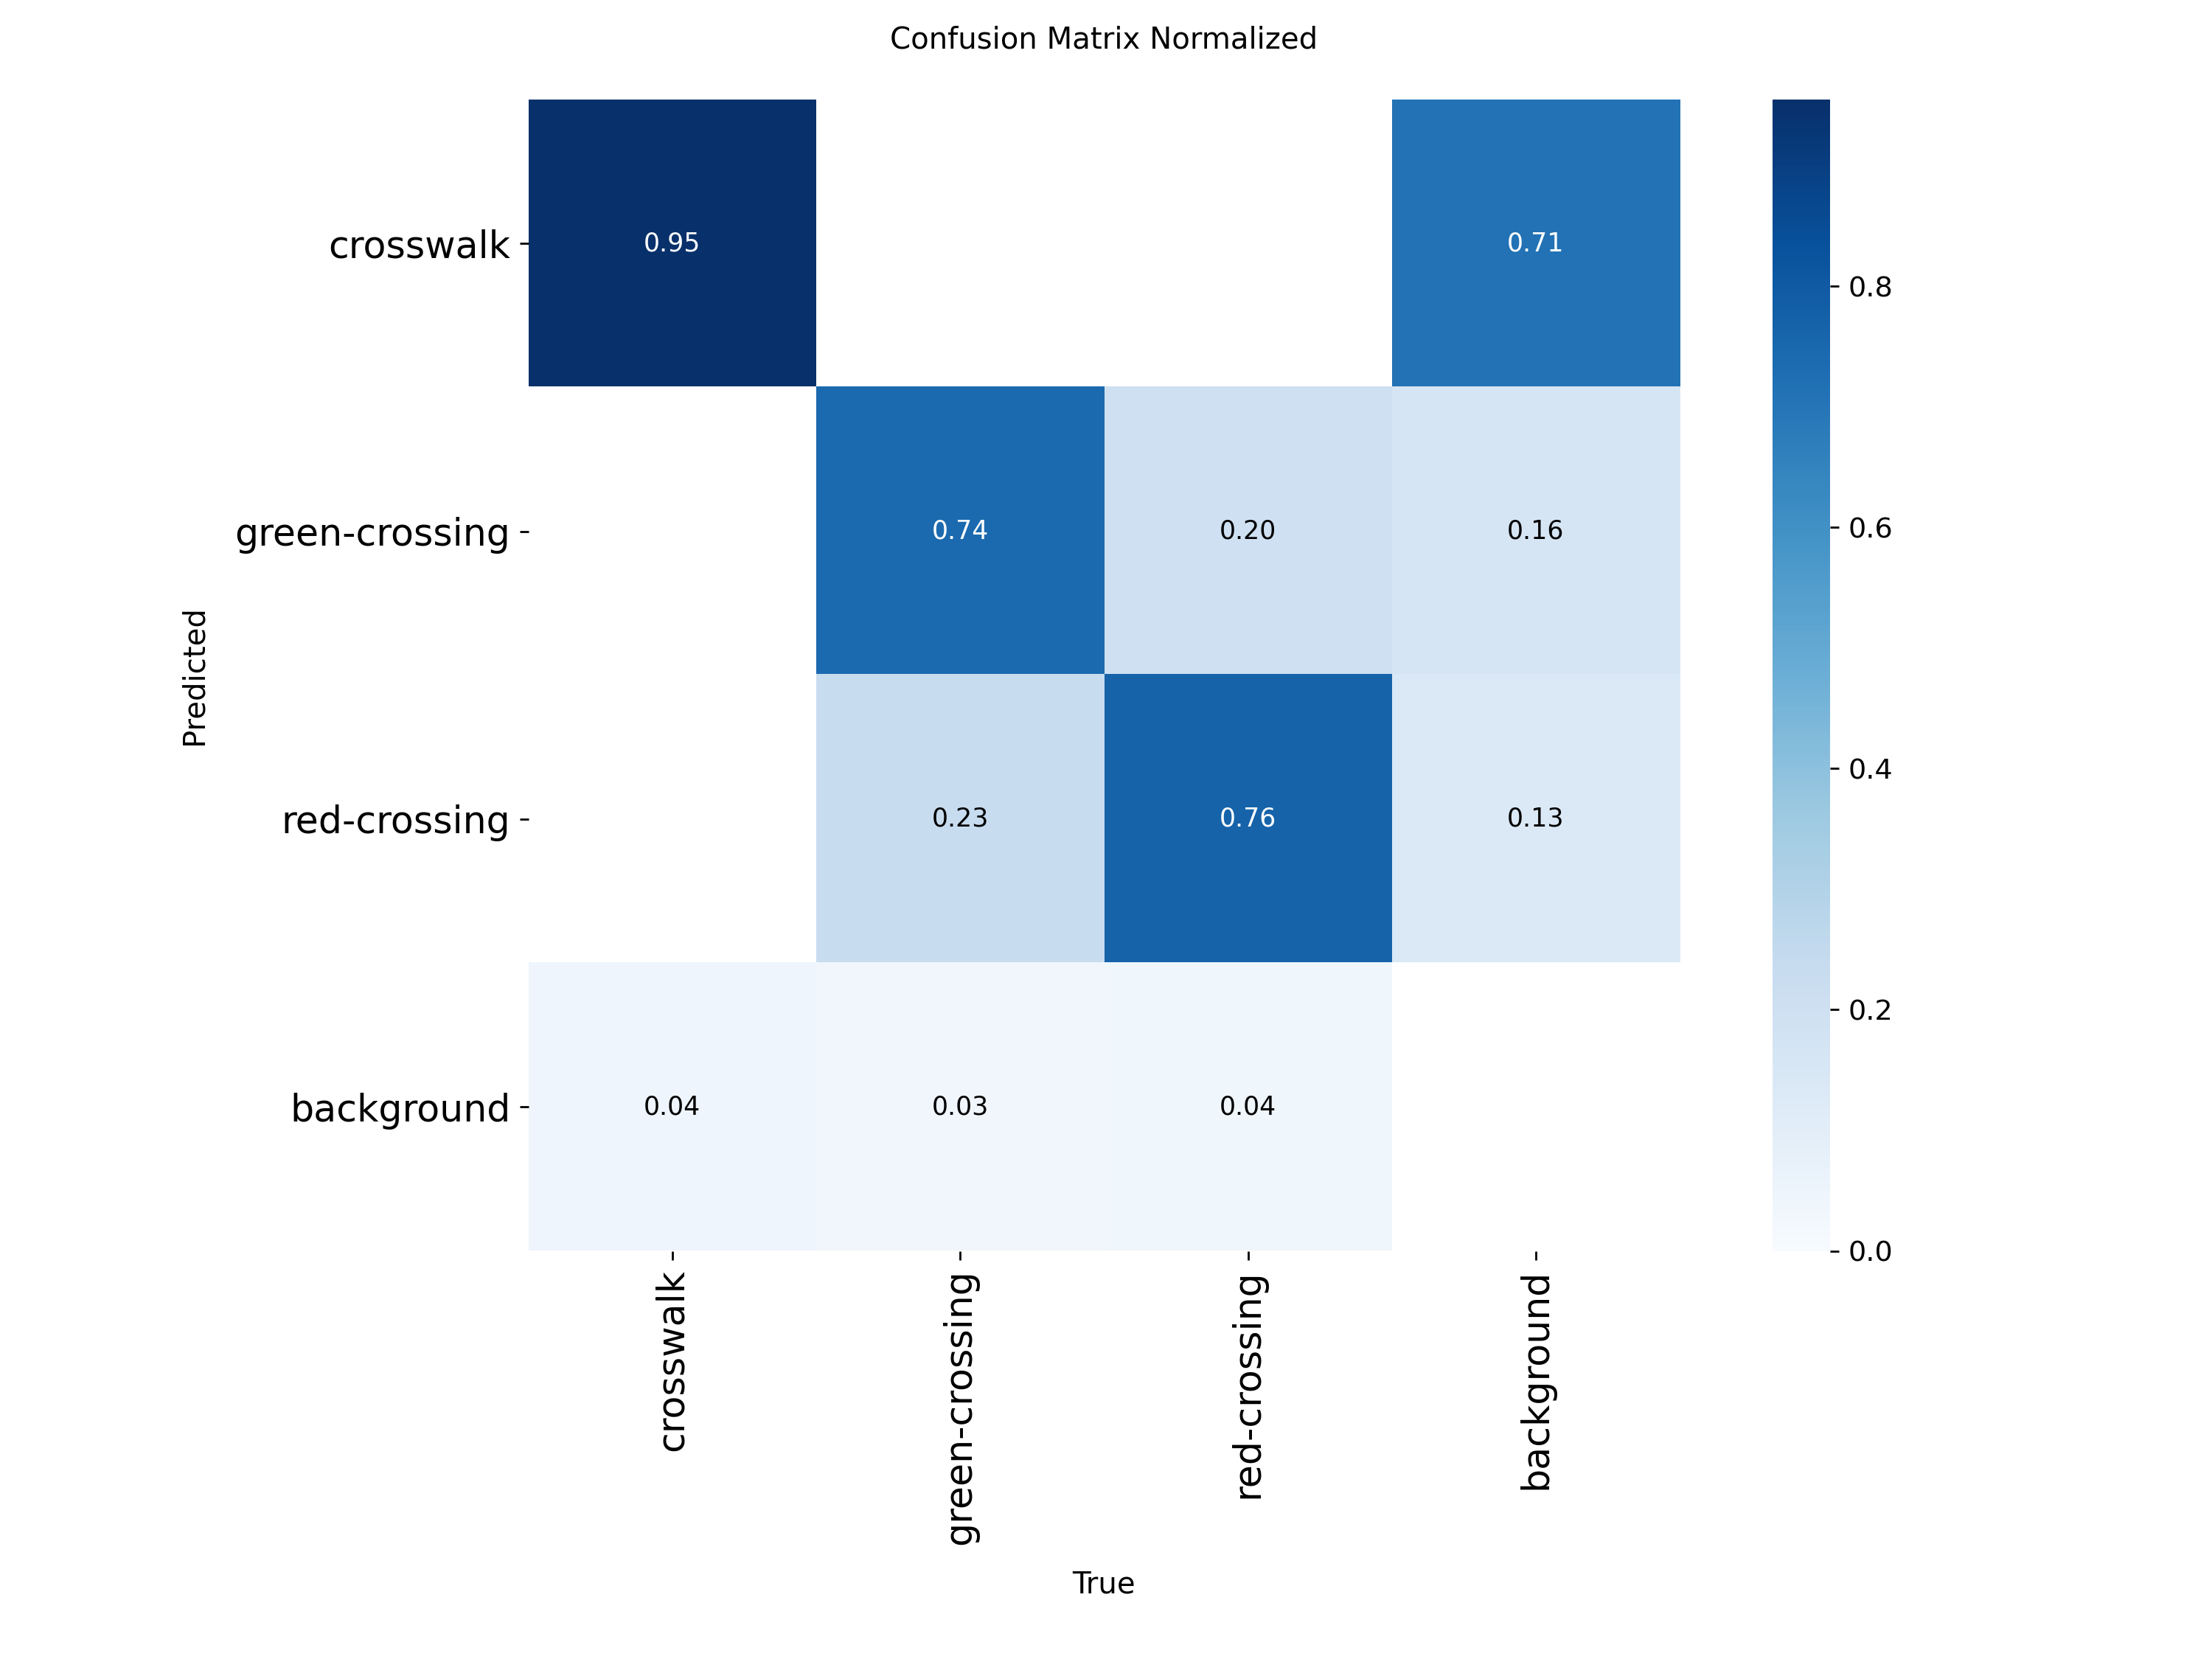

/kaggle/working/runs/yolo11s_640/results.png


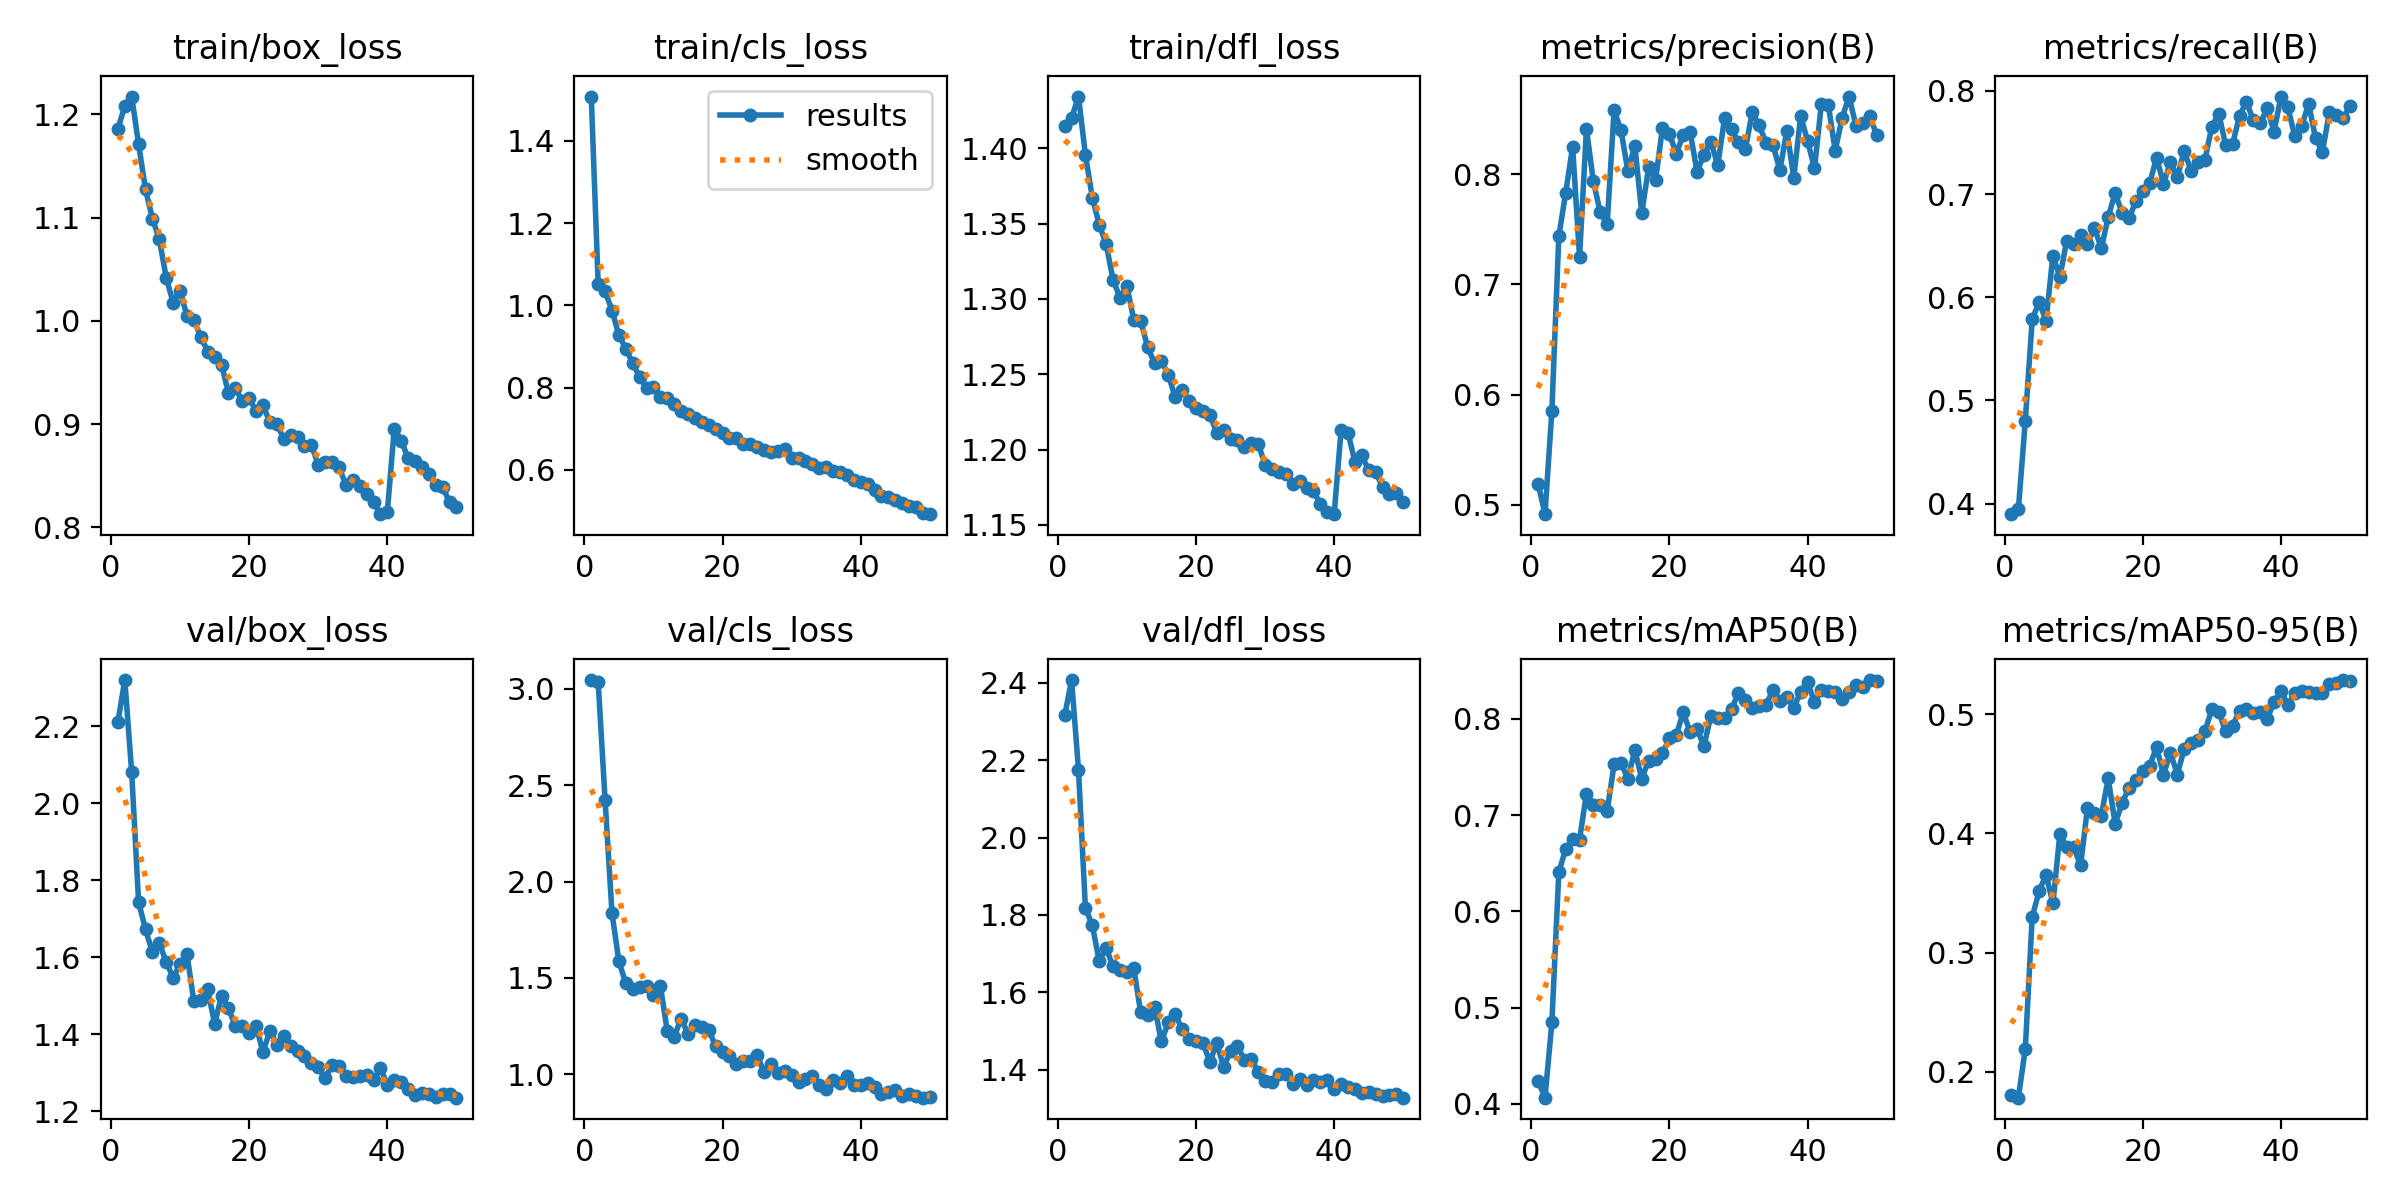

/kaggle/working/runs/test_yolo11s_640/confusion_matrix_normalized.png


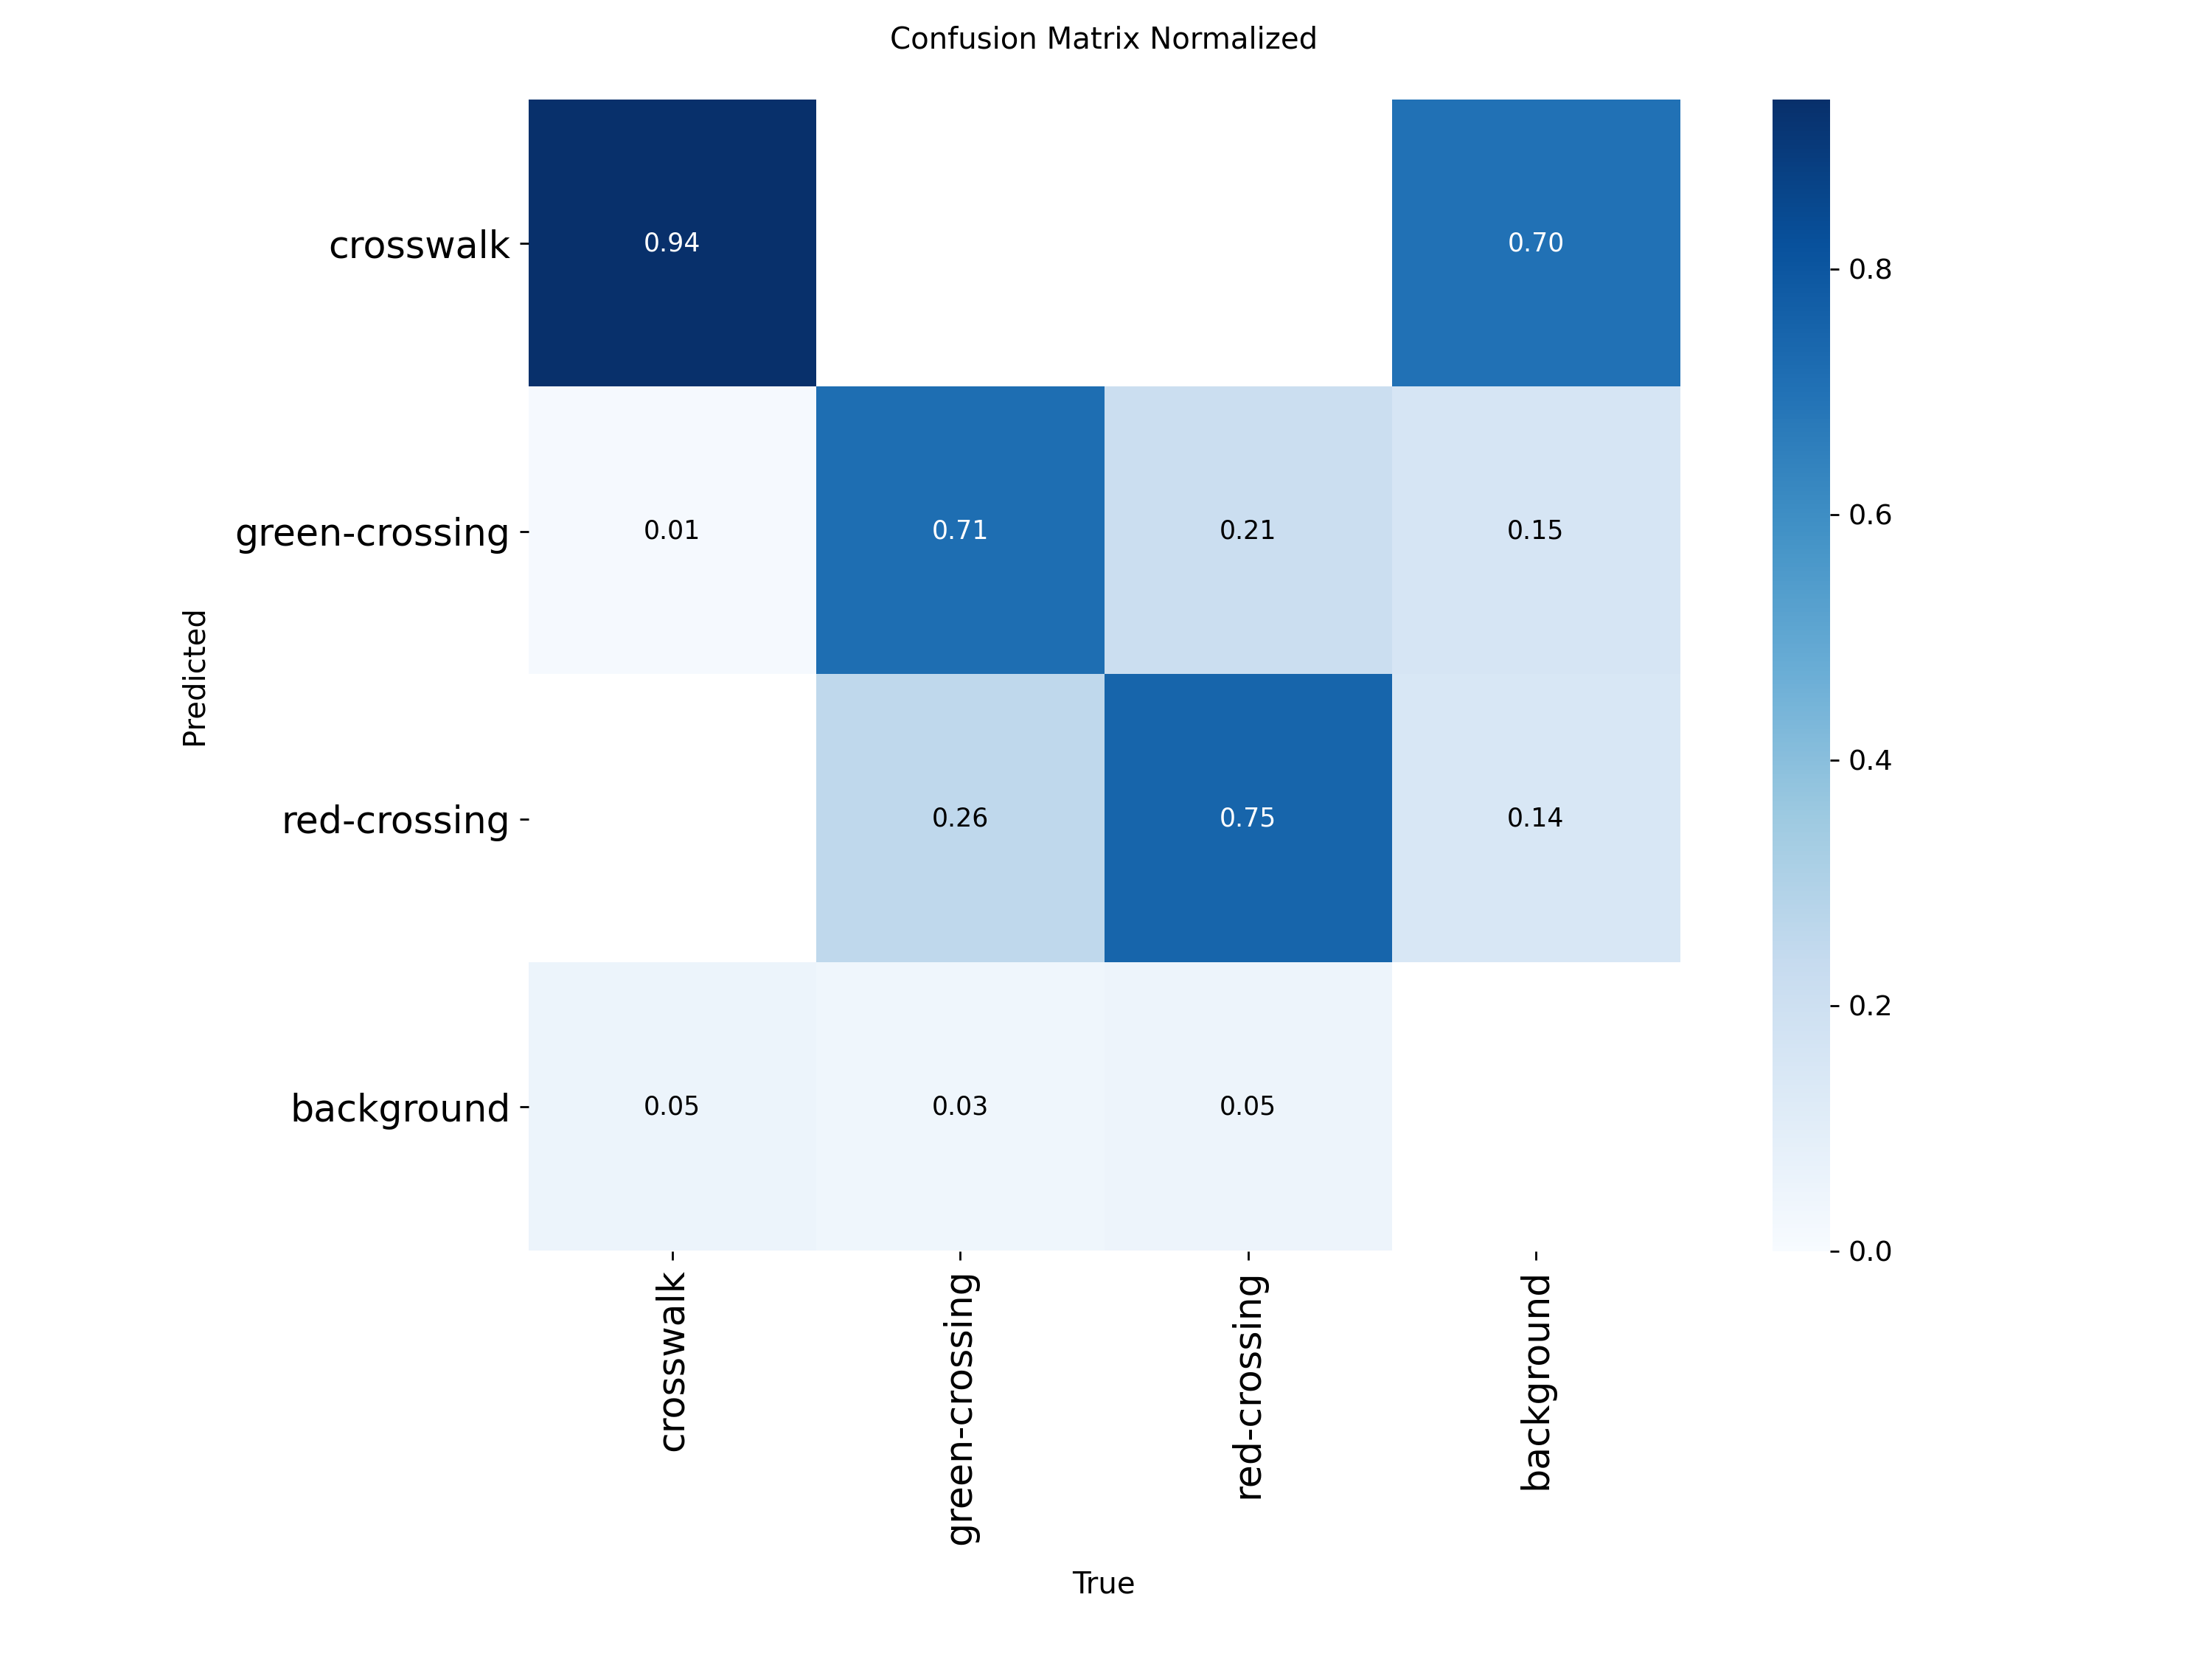

In [7]:
# 결과 그림: 모델별 학습 곡선 + 혼동행렬
from IPython.display import Image, display
for w in MODELS:
    tag = os.path.splitext(w)[0] + f'_{IMGSZ}'
    for f in [f'{OUT}/{tag}/results.png', f'{OUT}/test_{tag}/confusion_matrix_normalized.png']:
        if os.path.exists(f): print(f); display(Image(f, width=850))

## 5. (나중에) 고른 모델만 960 으로 재학습
비교가 끝난 뒤 따로 실행. `CHOSEN` 을 비교표 1등으로 바꿔.

In [8]:
RUN_960 = False                 # True 로 바꾸고 이 셀만 실행
CHOSEN = 'yolo26s.pt'           # 비교표 1등
if RUN_960:
    IMGSZ = 960
    tag = os.path.splitext(CHOSEN)[0] + '_960'
    YOLO(CHOSEN).train(data=DATA, imgsz=960, epochs=EPOCHS, batch=-1, device=0, workers=4,
                       seed=SEED, deterministic=False, project=OUT, name=tag, exist_ok=True)
    row = evaluate(f'{OUT}/{tag}/weights/best.pt', tag)
    pd.concat([pd.read_csv('/kaggle/working/compare.csv'), pd.DataFrame([row])]).to_csv('/kaggle/working/compare.csv', index=False)
    print(pd.DataFrame([row]).round(3).T)